# 03 · Patrones de quien se va y de quien se queda

Patrones más comunes de clientes que se van y que se quedan.

Dos enfoques complementarios:
A. Patrones frecuentes (estilo reglas de asociación): combinaciones de 1-3 características.
   - cobertura   = % del grupo (abandona / se queda) que cumple el patrón
   - tasa_churn  = % de los que cumplen el patrón que abandonan
   - lift        = tasa_churn / tasa global
   Se descartan patrones redundantes: un patrón largo solo se queda si mejora en >= 3 pp
   la tasa de todas sus versiones más cortas, y si no comparte más del 50% de sus clientes
   (Jaccard) con un patrón ya elegido.
B. Segmentos de un árbol de decisión poco profundo: reglas excluyentes que cubren a todos los clientes.

Salidas: `ml/reports/tables/patrones_*.csv`, `ml/reports/figures/patrones/*.png`

In [1]:
from itertools import combinations

import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

from telco import paths, style
from telco.data import load_clean

from telco.style import CHURN, MUTED, STAY

MIN_COVERAGE = 0.10   # patrón debe cubrir >= 10% de su grupo
MIN_GAIN_PP = 3       # mejora mínima vs. sub-patrones
MAX_OVERLAP = 0.5     # Jaccard máx. de clientes cubiertos entre dos patrones elegidos (diversidad)
TOP = 12
style.apply()
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

df = load_clean().drop(columns=["customer_id", "gender_male"])
y = df.pop("churn")
base = y.mean()

## 1. Ítems legibles
Cada característica binaria se convierte en «=si» / «=no»; antigüedad y cargo mensual, en tramos.

In [2]:
items: dict[str, np.ndarray] = {}
for c in df.columns:
    if c in ("tenure", "monthly_charges", "total_charges"):
        continue
    if "_" in c and c.split("_")[0] in ("contract", "internet", "payment"):
        items[c.replace("_service_", "=").replace("contract_", "contract=").replace("payment_method_", "pago=")] = (df[c] == 1).values
    else:
        items[f"{c}=si"] = (df[c] == 1).values
        items[f"{c}=no"] = (df[c] == 0).values
for lo, hi in [(0, 6), (7, 12), (13, 24), (25, 48), (49, 72)]:
    items[f"antigüedad {lo}-{hi}m"] = df.tenure.between(lo, hi).values
for lo, hi, name in [(0, 35, "<35"), (35, 70, "35-70"), (70, 90, "70-90"), (90, 1e9, ">90")]:
    items[f"cargo_mensual {name}"] = ((df.monthly_charges >= lo) & (df.monthly_charges < hi)).values
names = list(items)
M = np.column_stack([items[n] for n in names])
churn = y.values.astype(bool)
group = {"abandona": churn, "se_queda": ~churn}


def family(name: str) -> str:
    return name.split("=")[0].split(" ")[0]

## 2. Patrones frecuentes de quien se va y de quien se queda

In [3]:
rate: dict[frozenset, float] = {}
rows = []
for k in (1, 2, 3):
    for combo in combinations(range(len(names)), k):
        if len({family(names[i]) for i in combo}) < k:  # no mezclar valores de la misma variable
            continue
        mask = M[:, combo].all(axis=1)
        n = mask.sum()
        if n < 50:
            continue
        key = frozenset(combo)
        r = churn[mask].mean()
        rate[key] = r
        cov_churn, cov_stay = mask[churn].mean(), mask[~churn].mean()
        if max(cov_churn, cov_stay) < MIN_COVERAGE:
            continue
        rows.append({"key": key, "patron": " & ".join(names[i] for i in combo), "k": k, "n": n,
                     "cob_abandona": cov_churn * 100, "cob_se_queda": cov_stay * 100,
                     "tasa_churn": r * 100, "lift": r / base})
pat = pd.DataFrame(rows)


def not_redundant(row, direction: int) -> bool:
    subs = [frozenset(s) for j in range(1, row.k) for s in combinations(row.key, j)]
    return all(direction * (row.tasa_churn - rate[s] * 100) >= MIN_GAIN_PP for s in subs if s in rate)


def diverse(cands: pd.DataFrame) -> pd.DataFrame:
    """Greedy: recorre en orden y salta patrones que repiten los clientes de uno ya elegido."""
    chosen, masks = [], []
    for i, row in cands.iterrows():
        m = M[:, list(row.key)].all(axis=1)
        if all((m & o).sum() / (m | o).sum() <= MAX_OVERLAP for o in masks):
            chosen.append(i)
            masks.append(m)
        if len(chosen) == TOP:
            break
    return cands.loc[chosen]


leave = pat[(pat.cob_abandona >= MIN_COVERAGE * 100) & (pat.lift > 1)]
leave = diverse(leave[leave.apply(not_redundant, axis=1, direction=1)].sort_values("tasa_churn", ascending=False))
stay = pat[(pat.cob_se_queda >= MIN_COVERAGE * 100) & (pat.lift < 1)]
stay = diverse(stay[stay.apply(not_redundant, axis=1, direction=-1)].sort_values("tasa_churn"))

In [4]:
cols = ["patron", "n", "cob_abandona", "cob_se_queda", "tasa_churn", "lift"]
print(f"Tasa global de abandono: {base:.1%}\n")
print(f"A. PATRONES DE QUIEN SE VA (cubren >= {MIN_COVERAGE:.0%} de los que abandonan, mayor tasa de churn):")
print(leave[cols].round(1).to_string(index=False), "\n")
print(f"   PATRONES DE QUIEN SE QUEDA (cubren >= {MIN_COVERAGE:.0%} de los que se quedan, menor tasa de churn):")
print(stay[cols].round(1).to_string(index=False), "\n")
leave[cols].round(2).to_csv(paths.table("patrones_abandona.csv"), index=False)
stay[cols].round(2).to_csv(paths.table("patrones_se_queda.csv"), index=False)

Tasa global de abandono: 26.5%

A. PATRONES DE QUIEN SE VA (cubren >= 10% de los que abandonan, mayor tasa de churn):
                                                                patron    n  cob_abandona  cob_se_queda  tasa_churn  lift
          paperless_billing=si & antigüedad 0-6m & cargo_mensual 70-90  341          13.5           1.7        74.2   2.8
        paperless_billing=si & pago=electronic_check & antigüedad 0-6m  489          19.1           2.6        73.0   2.8
                online_security=no & streaming_tv=si & antigüedad 0-6m  264          10.1           1.4        71.6   2.7
                                 streaming_movies=si & antigüedad 0-6m  284          10.5           1.7        69.4   2.6
                                   multiple_lines=si & antigüedad 0-6m  291          10.6           1.8        68.4   2.6
      online_security=no & pago=electronic_check & cargo_mensual 70-90  684          22.4           5.1        61.3   2.3
                senior_citiz

## 3. Segmentos de un árbol de decisión
**Nota:** es un método supervisado (usa el abandono para partir). Describe reglas excluyentes, pero no
es un agrupamiento; la segmentación no supervisada está en el notebook 04 (K-Means).

In [5]:
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=150, random_state=42).fit(df, y)
t = tree.tree_


def rule(node: int, conds: list[str]) -> list[tuple[list[str], int]]:
    if t.children_left[node] == -1:
        return [(conds, node)]
    f, thr = df.columns[t.feature[node]], t.threshold[node]
    if set(df[f].unique()) <= {0, 1}:
        left, right = f"{f}=no", f"{f}=si"
    else:
        left, right = f"{f} <= {thr:.1f}", f"{f} > {thr:.1f}"
    return rule(t.children_left[node], conds + [left]) + rule(t.children_right[node], conds + [right])


FAMILIES = {"contract_": "contrato", "internet_service_": "internet", "payment_method_": "pago"}


def simplify(conds: list[str]) -> str:
    """Fusiona condiciones: one-hot de una misma variable y cotas de una misma numérica."""
    fam: dict[str, dict[str, list[str]]] = {}
    lo: dict[str, float] = {}
    hi: dict[str, float] = {}
    rest = []
    for c in conds:
        if " <= " in c or " > " in c:
            f, op, v = c.split(" ")
            (hi if op == "<=" else lo)[f] = min(hi.get(f, 1e9), float(v)) if op == "<=" else max(lo.get(f, -1e9), float(v))
            continue
        f, val = c.split("=")
        prefix = next((pre for pre in FAMILIES if f.startswith(pre)), None)
        if prefix:
            fam.setdefault(FAMILIES[prefix], {"si": [], "no": []})[val].append(f[len(prefix):])
        else:
            rest.append(c)
    out = []
    for pre, k in FAMILIES.items():
        if k not in fam:
            continue
        v = fam[k]
        left = [c[len(pre):] for c in df.columns if c.startswith(pre) and c[len(pre):] not in v["no"]]
        out.append(f"{k}={v['si'][0]}" if v["si"] else f"{k}={left[0]}" if len(left) == 1 else f"{k}≠{'/'.join(v['no'])}")
    for f in dict.fromkeys([*lo, *hi]):
        a, b = lo.get(f), hi.get(f)
        out.append(f"{a:g}<{f}≤{b:g}" if a is not None and b is not None else f"{f}>{a:g}" if a is not None else f"{f}≤{b:g}")
    return " · ".join(out + rest)


leaf_of = tree.apply(df)
seg = pd.DataFrame([{
    "segmento": simplify(c), "n": (leaf_of == node).sum(),
    "pct_clientes": (leaf_of == node).mean() * 100,
    "tasa_churn": y[leaf_of == node].mean() * 100,
} for c, node in rule(0, [])]).sort_values("tasa_churn", ascending=False)
seg["pct_de_abandonos"] = seg.n * seg.tasa_churn / 100 / y.sum() * 100
print("B. SEGMENTOS (árbol de decisión, profundidad 4, cada cliente cae en exactamente uno):")
print(seg.round(1).to_string(index=False), "\n")
seg.round(2).to_csv(paths.table("patrones_segmentos.csv"), index=False)

B. SEGMENTOS (árbol de decisión, profundidad 4, cada cliente cae en exactamente uno):
                                                                            segmento   n  pct_clientes  tasa_churn  pct_de_abandonos
    contrato=month_to_month · internet=fiber_optic · tenure≤15.5 · total_charges≤120 238           3.4        86.6              11.0
    contrato=month_to_month · internet=fiber_optic · total_charges>120 · tenure≤15.5 798          11.3        64.0              27.3
                                 contrato=month_to_month · internet=dsl · tenure≤5.5 463           6.6        50.8              12.6
contrato=month_to_month · internet=fiber_optic · pago=electronic_check · tenure>15.5 598           8.5        48.2              15.4
contrato=month_to_month · internet=fiber_optic · pago≠electronic_check · tenure>15.5 494           7.0        31.8               8.4
      contrato=month_to_month · internet≠fiber_optic · tenure>5.5 · phone_service=no 239           3.4        29.7  

## 4. Gráficos

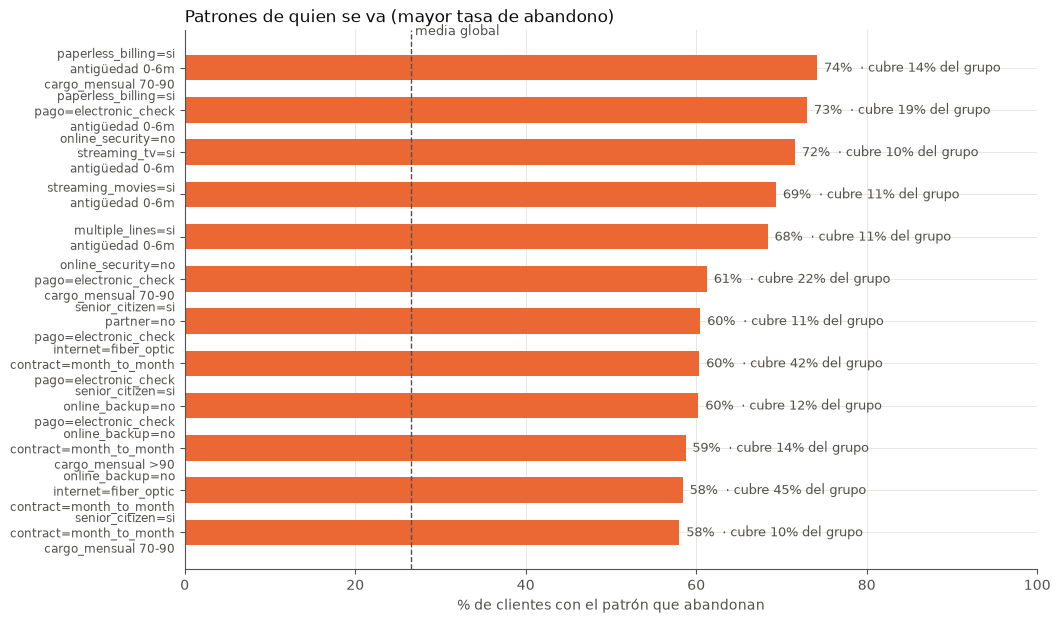

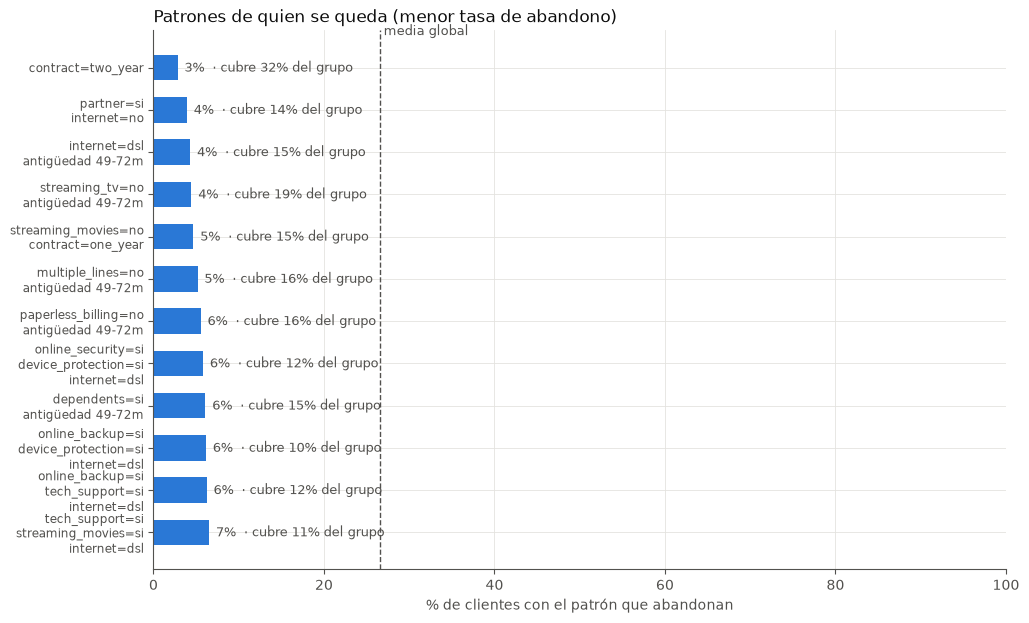

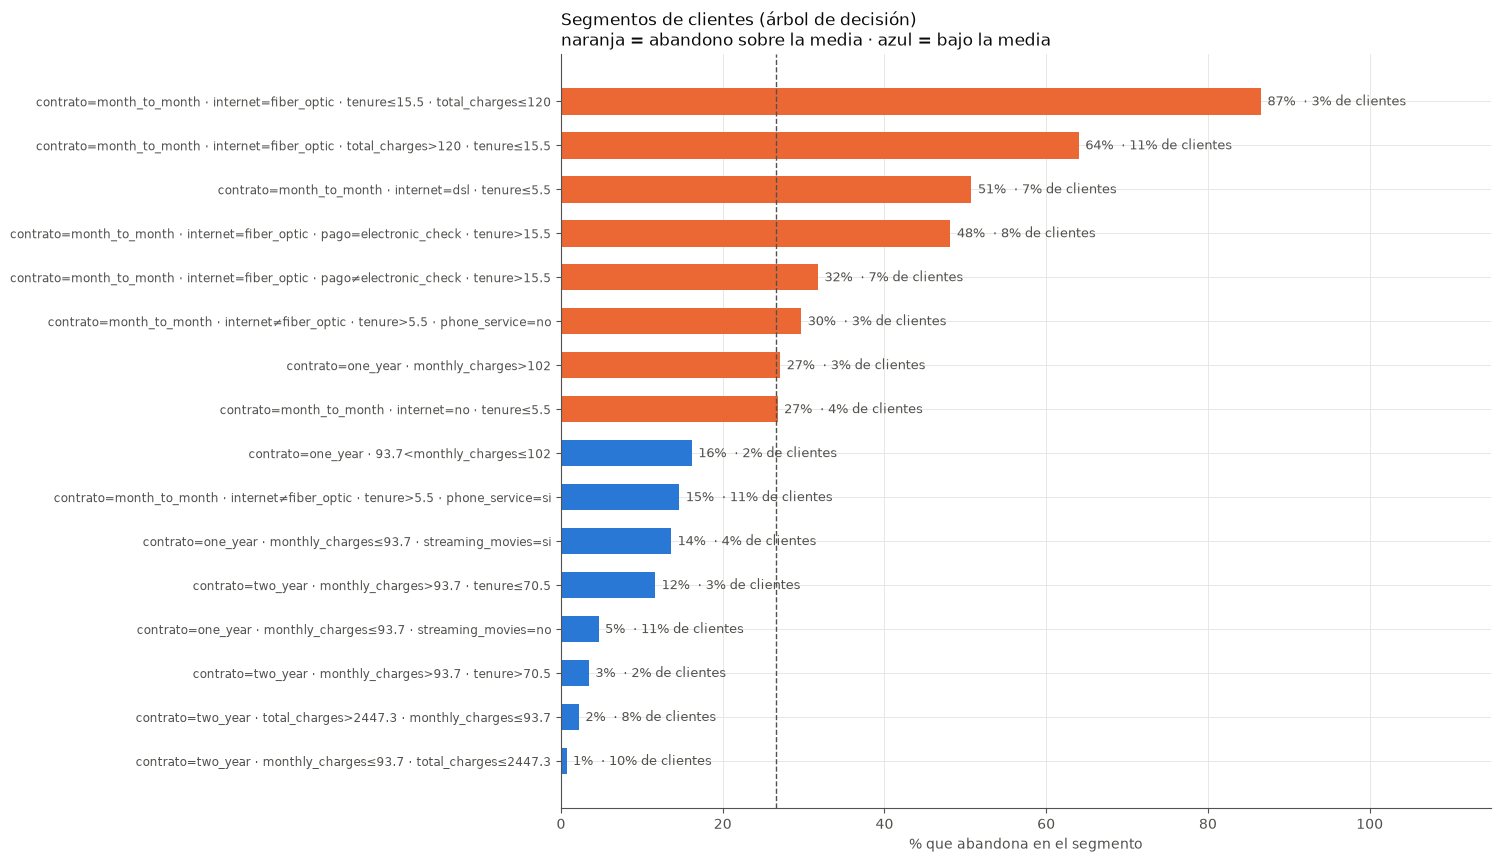

In [6]:
def plot_patterns(data: pd.DataFrame, color: str, cov_col: str, title: str, file: str) -> None:
    data = data.iloc[::-1]
    yy = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(data) + 1.6))
    ax.barh(yy, data.tasa_churn, color=color, height=0.6)
    ax.axvline(base * 100, color=MUTED, ls="--", lw=1)
    ax.text(base * 100, len(data) - 0.3, " media global", color=MUTED, fontsize=9, va="bottom")
    for yi, (r, cov) in enumerate(zip(data.tasa_churn, data[cov_col])):
        ax.text(r + 0.8, yi, f"{r:.0f}%  · cubre {cov:.0f}% del grupo", va="center", color=MUTED, fontsize=9)
    ax.set_yticks(yy, data.patron.str.replace(" & ", "\n", regex=False) if data.k.max() > 2 else data.patron, fontsize=8.5)
    ax.set_xlim(0, 100)
    ax.set_xlabel("% de clientes con el patrón que abandonan")
    ax.set_title(title, loc="left")
    style.save(fig, paths.figure("patrones", file))


plot_patterns(leave, CHURN, "cob_abandona", "Patrones de quien se va (mayor tasa de abandono)", "patrones_abandona.png")
plot_patterns(stay, STAY, "cob_se_queda", "Patrones de quien se queda (menor tasa de abandono)", "patrones_se_queda.png")

s = seg.iloc[::-1]
yy = np.arange(len(s))
fig, ax = plt.subplots(figsize=(12, 0.5 * len(s) + 1.8))
ax.barh(yy, s.tasa_churn, color=[CHURN if r > base * 100 else STAY for r in s.tasa_churn], height=0.6)
ax.axvline(base * 100, color=MUTED, ls="--", lw=1)
for yi, (r, p) in enumerate(zip(s.tasa_churn, s.pct_clientes)):
    ax.text(r + 0.8, yi, f"{r:.0f}%  · {p:.0f}% de clientes", va="center", color=MUTED, fontsize=9)
ax.set_yticks(yy, s.segmento, fontsize=8.5)
ax.set_xlim(0, 115)
ax.set_xlabel("% que abandona en el segmento")
ax.set_title("Segmentos de clientes (árbol de decisión)\nnaranja = abandono sobre la media · azul = bajo la media", loc="left")
style.save(fig, paths.figure("patrones", "patrones_segmentos.png"))